C:\Users\bsaurugg\AppData\Local\Temp\ipykernel_8484\1766498744.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


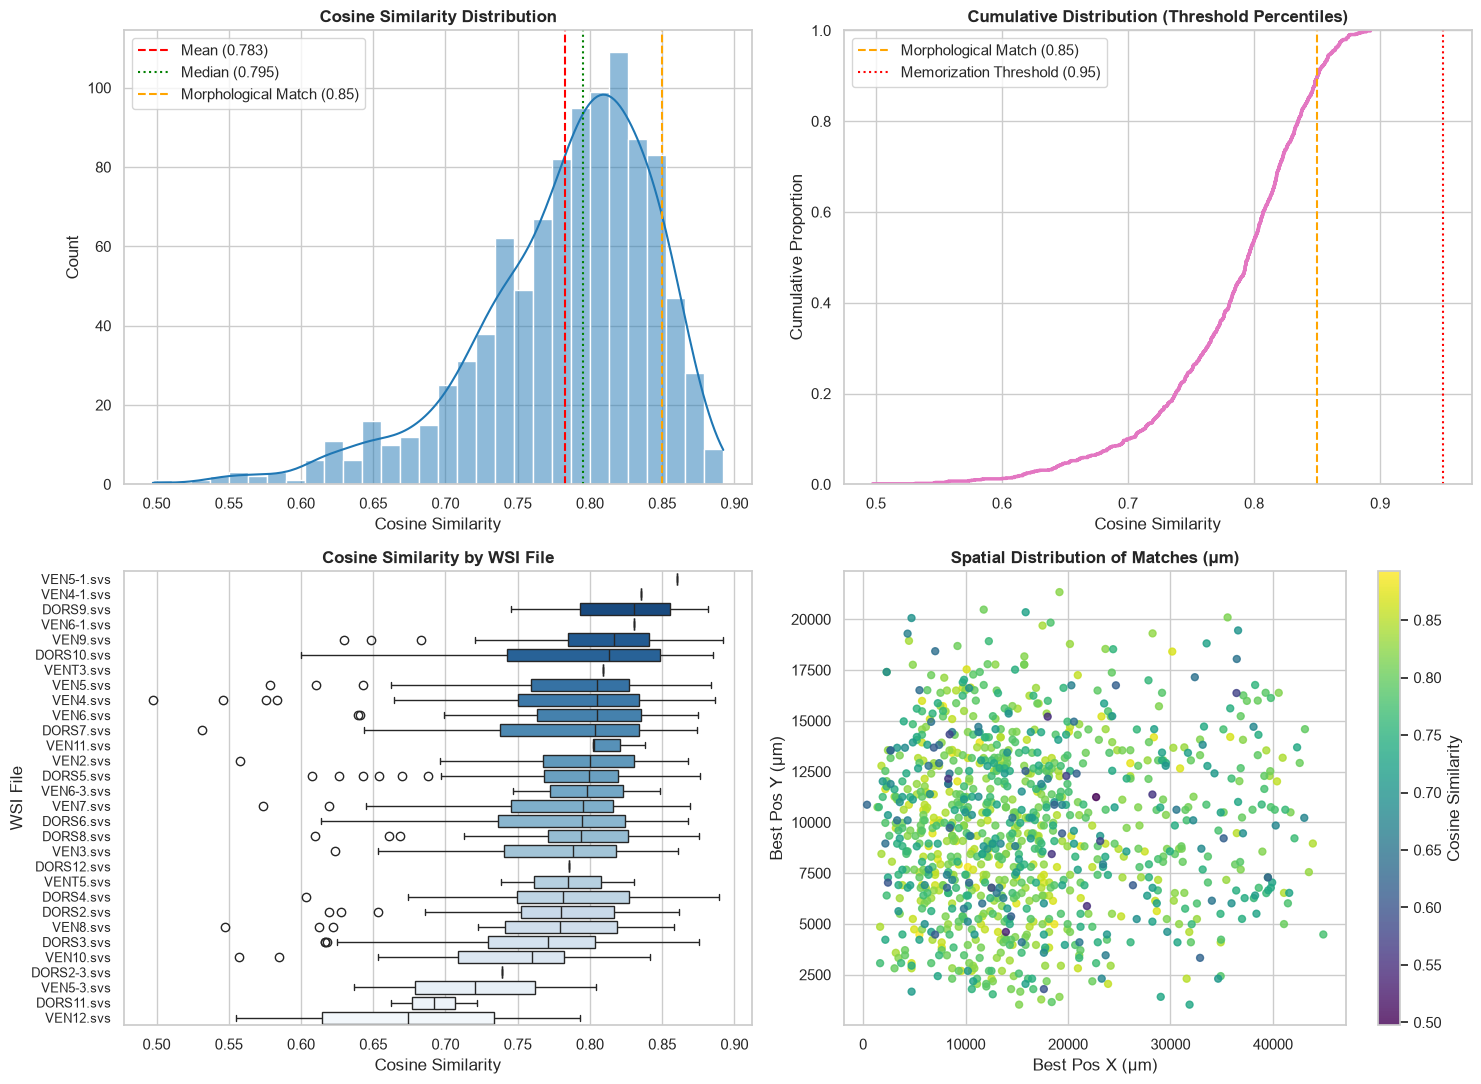

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

MORPHOLOGICAL_MATCH_CUTOFF = 0.85
MEMORIZATION_THRESHOLD = 0.95
MOST_FREQUENT_WSI_COUNT = 30

sns.set_theme(style="whitegrid")

# 1. Load data
df = pd.read_csv('uni2_wsi_search_results.csv')
df['wsi_file'] = df['wsi_file'].str.replace('_COPY', '', regex=False)

# 2. Create figure grid
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# ---------------------------------------------------------
# Plot 1: Histogram & KDE Density
# ---------------------------------------------------------
sns.histplot(df['cosine_similarity'], kde=True, ax=axes[0, 0], color='#1f77b4', bins=30)
mean_val = df['cosine_similarity'].mean()
median_val = df['cosine_similarity'].median()

axes[0, 0].axvline(mean_val, color='red', linestyle='--', label=f'Mean ({mean_val:.3f})')
axes[0, 0].axvline(median_val, color='green', linestyle=':', label=f'Median ({median_val:.3f})')
axes[0, 0].axvline(MORPHOLOGICAL_MATCH_CUTOFF, color='orange', linestyle='--', label=f'Morphological Match ({MORPHOLOGICAL_MATCH_CUTOFF})')
# axes[0, 0].axvline(MEMORIZATION_THRESHOLD, color='red', linestyle=':', label=f'Memorization Threshold ({MEMORIZATION_THRESHOLD})')
axes[0, 0].set_title('Cosine Similarity Distribution', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Cosine Similarity')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend()

# ---------------------------------------------------------
# Plot 2: Empirical Cumulative Density (ECDF) for Thresholding
# ---------------------------------------------------------
sns.ecdfplot(data=df, x='cosine_similarity', ax=axes[0, 1], color='#e377c2', linewidth=2.5)
axes[0, 1].axvline(MORPHOLOGICAL_MATCH_CUTOFF, color='orange', linestyle='--', label=f'Morphological Match ({MORPHOLOGICAL_MATCH_CUTOFF})')
axes[0, 1].axvline(MEMORIZATION_THRESHOLD, color='red', linestyle=':', label=f'Memorization Threshold ({MEMORIZATION_THRESHOLD})')
axes[0, 1].set_title('Cumulative Distribution (Threshold Percentiles)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Cosine Similarity')
axes[0, 1].set_ylabel('Cumulative Proportion')
axes[0, 1].legend(loc='upper left')

# ---------------------------------------------------------
# Plot 3: Horizontal Boxplot
# ---------------------------------------------------------
top_wsis = df['wsi_file'].value_counts().head(MOST_FREQUENT_WSI_COUNT).index
df_top_wsi = df[df['wsi_file'].isin(top_wsis)]
wsi_order = df_top_wsi.groupby('wsi_file')['cosine_similarity'].median().sort_values(ascending=False).index

sns.boxplot(
    data=df_top_wsi, 
    y='wsi_file', 
    x='cosine_similarity', 
    order=wsi_order, 
    ax=axes[1, 0], 
    palette='Blues_r'
)
axes[1, 0].set_title('Cosine Similarity by WSI File', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('WSI File')
axes[1, 0].set_xlabel('Cosine Similarity')
axes[1, 0].tick_params(axis='y', labelsize=9)

# ---------------------------------------------------------
# Plot 4: Spatial Distribution Map
# ---------------------------------------------------------
sc = axes[1, 1].scatter(
    df['best_pos_um_x'], 
    df['best_pos_um_y'], 
    c=df['cosine_similarity'], 
    cmap='viridis', 
    s=25, 
    alpha=0.8
)
cbar = fig.colorbar(sc, ax=axes[1, 1])
cbar.set_label('Cosine Similarity')
axes[1, 1].set_title('Spatial Distribution of Matches (µm)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Best Pos X (µm)')
axes[1, 1].set_ylabel('Best Pos Y (µm)')

plt.tight_layout()
plt.show()

# # ---------------------------------------------------------
# # Generate Descriptive Summary Table
# # ---------------------------------------------------------
# sims = df['cosine_similarity']
# summary_table = pd.DataFrame({
#     'Metric': [
#         'Total Samples (N)',
#         'Mean Similarity',
#         'Std Deviation',
#         'Min Similarity',
#         '25th Percentile (Q1)',
#         'Median (50th Percentile)',
#         '75th Percentile (Q3)',
#         'Max Similarity',
#         'High-Confidence Matches (≥ 0.75)',
#         'Suspected Memorization (≥ 0.95)'
#     ],
#     'Value': [
#         f"{len(sims)}",
#         f"{sims.mean():.4f}",
#         f"{sims.std():.4f}",
#         f"{sims.min():.4f}",
#         f"{sims.quantile(0.25):.4f}",
#         f"{sims.median():.4f}",
#         f"{sims.quantile(0.75):.4f}",
#         f"{sims.max():.4f}",
#         f"{(sims >= 0.75).sum()} ({(sims >= 0.75).mean()*100:.1f}%)",
#         f"{(sims >= 0.95).sum()} ({(sims >= 0.95).mean()*100:.1f}%)"
#     ]
# })

# print("==================================================")
# print("       DESCRIPTIVE STATISTICAL ANALYSIS           ")
# print("==================================================")
# print(summary_table.to_string(index=False))